# Curso: Redes Neurais Convolucionais

Prof. [Denilson Alves Pereira](https://sites.google.com/ufla.br/denilsonpereira) <br>
Departamento de Ciência da Computação (DCC) <br>
Instituto de Ciências Exatas e Tecnológicas (ICET) <br> 
Universidade Federal de Lavras (UFLA)

## Detecção de Faces

**Objetivo**: apresentar um exemplo de detecção de faces usando a biblioteca MTCNN.

**Você vai aprender a**:
- Utilizar um modelo de aprendizagem para detecção de faces
- Enquadrar e extrair as faces de pessoas existente em uma fotografia

Versão: Agosto, 2021

Detecção de Face (*Face Detection*) é o processo de localizar automaticamente as faces em uma fotografia. A localização é marcada por uma caixa retangular enquadrando a face detectada.
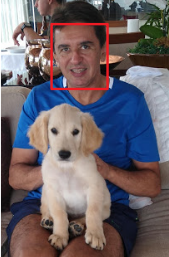

O MTCNN (*Multi-Task Cascaded Convolutional Neural Network*) é um modelo de aprendizagem para detecção de face descrito no artigo intitulado ["Joint Face Detection and Alignment Using Multitask Cascaded Convolutional Networks"](https://arxiv.org/abs/1604.02878).

Uma implementação desse modelo pode ser instalada pelo comando: <br>
pip install mtcnn

Código adaptado de https://machinelearningmastery.com/how-to-develop-a-face-recognition-system-using-facenet-in-keras-and-an-svm-classifier/

## Pacotes

In [1]:
import numpy as np # scientific computing
import matplotlib.pyplot as plt # scientific plotting library
from PIL import Image # image class
import mtcnn # face detection library

## Extração da Primeira Face

In [2]:
# load image from file
image = Image.open('./figs/face-detection-2.png')
# convert to RGB, if needed
image = image.convert('RGB')
# convert to numpy array
pixels = np.asarray(image)

In [3]:
# create the detector, using default weights
detector = mtcnn.MTCNN()
# detect faces in the image
faces = detector.detect_faces(pixels)

In [4]:
faces

[{'box': [58, 30, 48, 61],
  'confidence': 0.999962329864502,
  'keypoints': {'left_eye': (70, 55),
   'right_eye': (91, 52),
   'nose': (81, 68),
   'mouth_left': (74, 78),
   'mouth_right': (93, 76)}}]

In [5]:
# extract the bounding box from the first face
x1, y1, width, height = faces[0]['box']
x1, y1 = abs(x1), abs(y1) # bug fix
x2, y2 = x1 + width, y1 + height

In [6]:
# extract the face
face = pixels[y1:y2, x1:x2]

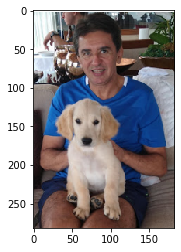

In [7]:
plt.imshow(pixels)

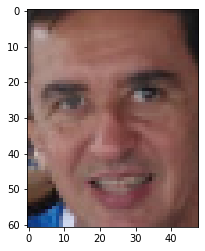

In [8]:
plt.imshow(face)

## Extração de Todas as Faces

In [9]:
# load image from file
image = Image.open('./figs/obama-michelle.jpeg')
# convert to RGB, if needed
image = image.convert('RGB')
# convert to numpy array
pixels = np.asarray(image)

In [10]:
# detect faces in the image
faces = detector.detect_faces(pixels)

In [11]:
# extract the bounding box from faces
face_pixels = {}
for i in range(0,len(faces)):
    x1, y1, width, height = faces[i]['box']
    x1, y1 = abs(x1), abs(y1) # bug fix
    x2, y2 = x1 + width, y1 + height
    # extract the face
    face_pixels[i] = pixels[y1:y2, x1:x2]

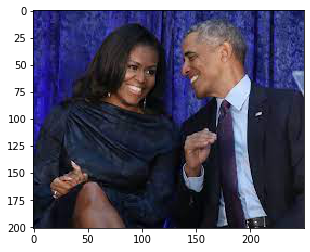

In [12]:
plt.imshow(pixels)

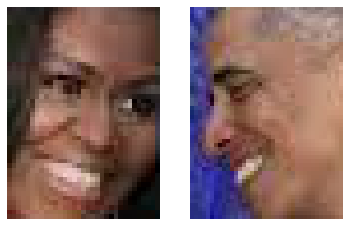

In [13]:
for (id, face_pix) in face_pixels.items():
    plt.subplot(1, len(face_pixels), id+1)
    plt.axis('off')
    plt.imshow(face_pix)
plt.show()

# Fim

Esses foram os passos para detecção de faces usando a biblioteca MTCNN..

--------------------------------